In [1]:
import numpy as np
from scipy import stats as st
from matplotlib import pyplot as plt
from sklearn.neighbors import KernelDensity as KD
import scipy.stats as stats

# The irreducible mass of black holes
For a BH of mass $M$ spin $\chi\in [0,1]$, the irreducible mass is 
\begin{equation}
M_{\rm irr} = %\sqrt{\frac{M^2+\sqrt{M^4-S^2}}{2}} = 
 M \sqrt{\frac{1+\sqrt{1-\chi^2}}{2}}
\label{mirrdef}
\end{equation}
For convenience, let us define 

$$f(\chi) = \sqrt{\frac{1+\sqrt{1-\chi^2}}{2}}$$

Suppose you have repeated measurments of $M$ and $\chi$. This is just because we're still frequentists for now. When we will put our Bayesian hat on, these distributions will be the *posterior samples* from a single measurement.

Let's assume that

- the spin $\chi$ is uniformly distributed between 0 and 1.
- the mass $M$ is normally distributed with mean $\mu$ and standard deviation $\sigma$.
- (masses and spins are uncorrelated)

These are simplistic assumption that, however, are not too far from what we are now measuring with gravitational-wave detectors. It's a toy model, but not a totally unreasonable one.

**Tasks**:

1. Start with a value of $\sigma=0.02$. Note that $\mu$ is a scale and not a parameter: you can normalize all quantities with a dimension of mass by $\mu$. Just set $\mu=1$ in your code and remember that all masses in the problem are measured in units of $\mu$. 

2. Plot the resulting pdf of $M_{\rm irr}$. First try an histogram with one the rules of thumb we've seen above.

*Hint (for point 2)*: You don't know the functional form of the pdf of $M_{\rm irr}$... but you don't need it if you just want to generate samples! That's the nice thing about numerics!

3. Using the same samples, plot the distribution of $M_{\rm irr}$ using a KDE.

4. Compute the KS distance between ${M_{\rm irr}}/\mu$ and ${f}$ as a function of $\sigma$. Discuss the limits at large and small values of $\sigma$. 

5. Compute the KS distance between ${M_{\rm irr}}$ and $M$ as a function of $\sigma$. Discuss the limits at large and small values of $\sigma$.

*Hint (for points 4 and 5)*. This is a KS test between two sets for samples, `scipy.stats.ks_2samp`.

You should find that (i) $M_{\rm irr}$ is distributed like $f$ if ${\sigma}\ll \mu$ and (ii) $M_{\rm irr}$ is distributed like $M$ if  $\sigma\gg \mu$.


7. [**Optional, not examinable**] Compute the pdf of $f$ from its mathematical definition (pen and paper!). Verify this result: 

\begin{equation}
\pi(f) = 2\frac{2 f^2-1}{\sqrt{1 - f^2}}\,.
\end{equation}

8. [**Optional, not examinable**]  Compute the pdfs of $M_{\rm irr}$ from its mathematical definition (pen and paper!). Verify this result:

\begin{equation}
p(M_{\rm irr})  = \frac{\sqrt{2/\pi}}{\sigma} \int_{1/\sqrt{2}}^1 \exp\left[{-\frac{(M_{\rm irr}/f -\mu)^2}{2\sigma^2}}\right]  \frac{2 f^2-1}{f \sqrt{1 - f^2}}  \,\, {\rm d}f\,. \label{pmirr}
\end{equation}

The this expression is only semi-analytic; that integral should then be solved numerically.

*Hint (for point 8)*: You want to use [this theorem](https://en.wikipedia.org/wiki/Distribution_of_the_product_of_two_random_variables) for the product of two random variables. 

9. Using the expressions from point 7 and 8, plot those pdfs check that they agree with your KDE reconstructions.

In [2]:
def f_chi(x):
    return np.sqrt((1+np.sqrt(1-x**2))/2)

def kde_sklearn(data, bandwidth = 1.0, kernel="linear"):
    kde_skl = KD(bandwidth = bandwidth, 
                            kernel=kernel)
    kde_skl.fit(data[:, np.newaxis])
    log_pdf = kde_skl.score_samples(xgrid[:, np.newaxis]) # sklearn returns log(density)
    return np.exp(log_pdf)

def scott(sig, N):
    return 3.5*sig/np.pow(N, 1/3)

### Task 1

In [3]:
sig = 0.02
mu = 1
size = 1000

chi = np.random.uniform(0, 1, size)
M = np.random.normal(mu, sig, size)
f = f_chi(chi)
M_irr = M*f

xgrid = np.linspace(M_irr.min(), M_irr.max(),1000)

Let's also plot $f(\chi)$ and $M$

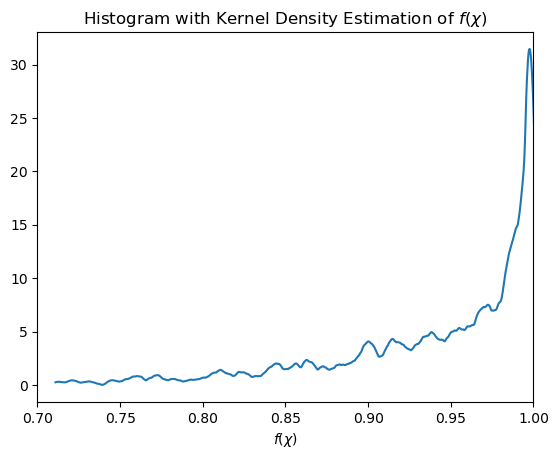

In [40]:
PDF_f = kde_sklearn(f ,bandwidth=0.005,kernel="epanechnikov")

plt.plot(xgrid,PDF_f)
plt.xlabel(r"$f(\chi)$")
plt.xlim(0.7, 1)
plt.title(r"Histogram with Kernel Density Estimation of $f(\chi)$")
plt.show()

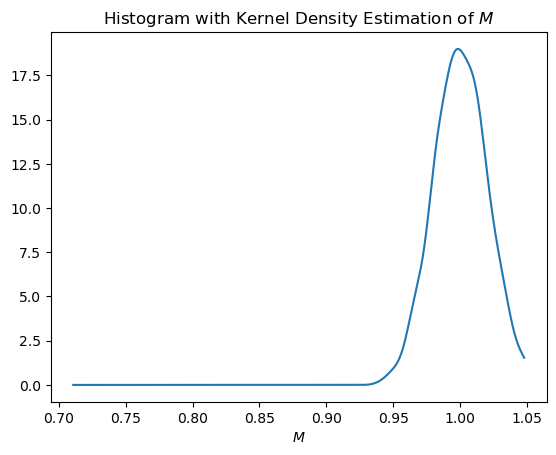

In [13]:
PDF_M = kde_sklearn(M ,bandwidth=0.005,kernel="gaussian")

plt.plot(xgrid,PDF_M)
plt.xlabel(r"$M$")
plt.title(r"Histogram with Kernel Density Estimation of $M$")
plt.show()

### Task 2
**"Scott's rule"**: $\Delta_b = \frac{3.5\sigma}{N^{1/3}}.$

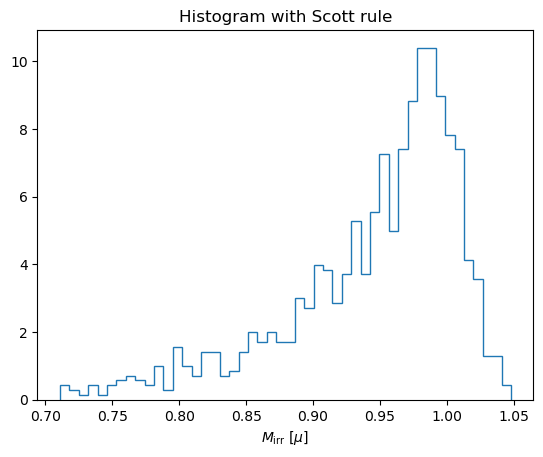

In [6]:
thumb = scott(sig, size)
bins = int((np.max(M_irr) - np.min(M_irr))//thumb)

plt.hist(M_irr, bins=bins, density=True, histtype="step")
plt.xlabel(r"$M_{\rm{irr}}$ $[\mu]$")
plt.title("Histogram with Scott rule")
plt.show()

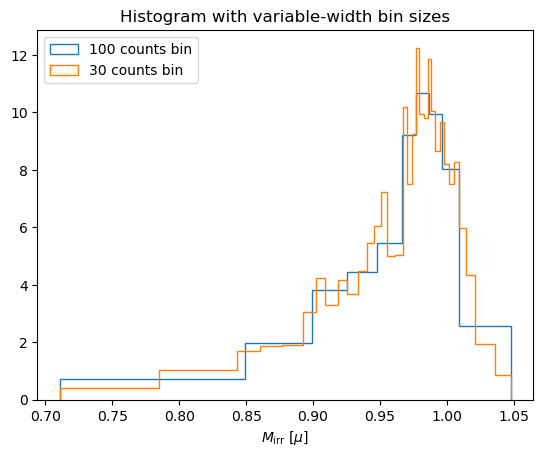

In [7]:
bins100 = np.append(np.sort(M_irr)[::100], np.max(M_irr)) 
bins30 = np.append(np.sort(M_irr)[::30], np.max(M_irr))
plt.hist(M_irr, bins=bins100, density=True, histtype="step", label = "100 counts bin") 
plt.hist(M_irr, bins=bins30, density=True, histtype="step", label = "30 counts bin")
plt.xlabel(r"$M_{\rm{irr}}$ $[\mu]$")
plt.title("Histogram with variable-width bin sizes")
plt.legend()
plt.show()

### Task 3

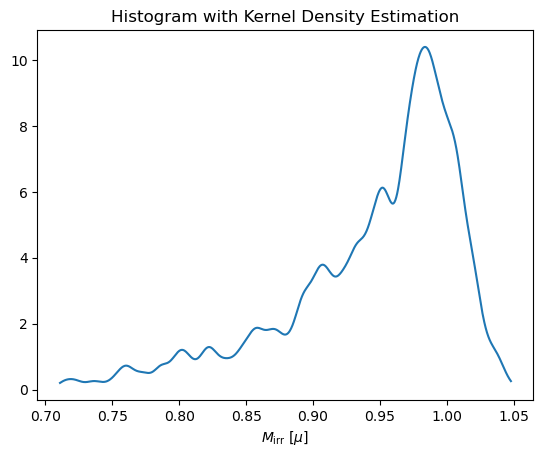

In [8]:
PDFtophat = kde_sklearn(M_irr,bandwidth=0.005,kernel="gaussian")

plt.plot(xgrid,PDFtophat)
plt.xlabel(r"$M_{\rm{irr}}$ $[\mu]$")
plt.title("Histogram with Kernel Density Estimation")
plt.show()

In [9]:
k = stats.ks_2samp(M_irr,f)
print(stats.ks_2samp(M_irr,f).statistic)

0.174


### Task 4

In [14]:
sigma = np.logspace(-4, 4, 1000)

M_sig = np.array([np.random.normal(mu, sigma_i, size) for sigma_i in sigma])
Mirr_sig = M_sig * f

ks_f = np.array([stats.ks_2samp(Mirr_sig[i,:],f).statistic for i in range(len(Mirr_sig))])

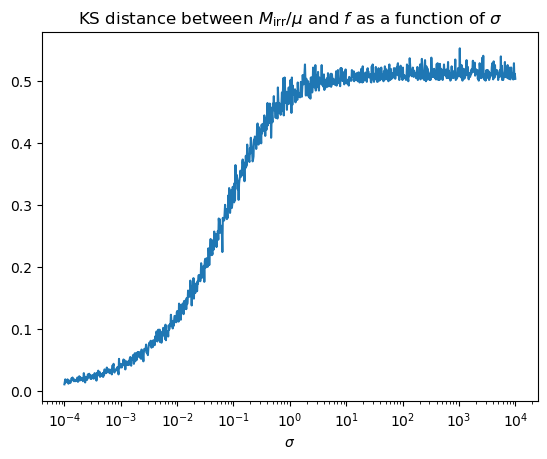

In [15]:
plt.plot(sigma, ks_f)
plt.title(r"KS distance between ${M_{\rm irr}}/\mu$ and ${f}$ as a function of $\sigma$")
plt.xscale('log')
plt.xlabel(r"$\sigma$")
plt.show()

### Task 5

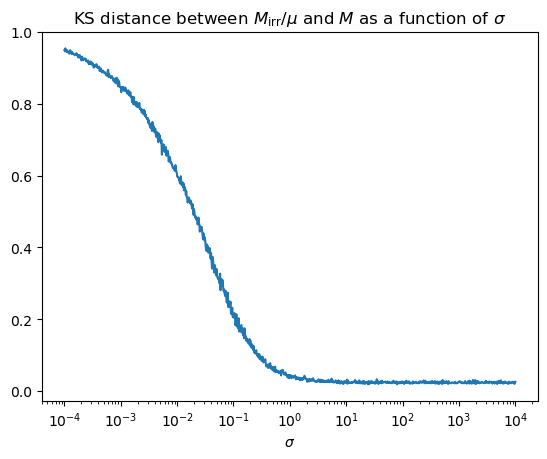

In [16]:
ks_M = np.array([stats.ks_2samp(Mirr_sig[i,:], M_sig[i, :]).statistic 
                 for i in range(len(Mirr_sig))])
plt.plot(sigma, ks_M)
plt.title(r"KS distance between ${M_{\rm irr}}/\mu$ and ${M}$ as a function of $\sigma$")
plt.xscale('log')
plt.xlabel(r"$\sigma$")
plt.show()

$M_{\rm irr}$ is distributed like $f$ if ${\sigma}\ll \mu$ and $M_{\rm irr}$ is distributed like $M$ if  $\sigma\gg \mu$, why?

I would say. For small values of $\sigma$, the masses $M$ are concentrated around $1$. In the limit for ${\sigma}\ll \mu$, $M \simeq 1$. So $M_\rm{irr} \simeq 1 \cdot f \simeq f$. In the opposite limit, we can consider the variance of $f$ to be really small with respect to $M$, and what we just said applies again.

In general, the Variable with the bigger Variance acts more as a dominant shape factor, while the Variable with the smaller one acts more as a scaling factor. 

### Task 6
We need to use the **Probability Integral Transform**. If $X$ is a uniform random variable $U(0, 1)$ and we define $Y = g(X)$, the PDF of $Y$ is found using:$$\pi(y) = p_X(x) \cdot \left| \frac{dx}{dy} \right|$$Since $X \sim U(0, 1)$, its density $p_X(x) = 1$ for $x \in [0,1]$. Therefore, the density of $f$ is simply the absolute value of the derivative of the inverse function:$$\pi(f) = \left| \frac{dx}{df} \right|$$
We find that $\frac{dx}{df} = 2 \frac{1-2f^2}{\sqrt{1-f^2}}$, but since $\frac{dx}{df} < 0$ ($f = 1$ for $\chi = 0$ and $f = 1/\sqrt2$ for $\chi = 1$)
$$\pi(f) =\left|\frac{dx}{df}\right| = 2 \frac{2f^2-1}{\sqrt{1-f^2}}$$

### Tak 7
If $X$ and $Y$ are two independent, continuous random variables, described by probability density functions $f_X$ and $f_Y$ then the probability density function of $Z=XY$ is:
$$f_{M_{irr}}(z) = \int_{-\infty}^{\infty} f_M(z/y) f_Y(y) \frac{1}{|y|} dy$$
In our case $X=M$ and $\pi_M \sim \mathcal{N}(\mu, \sigma)$, while $Y = f$ and $\pi_f$ was derived in the previous point:
$$\pi(M_{irr}) = \int_{f_{min}}^{f_{max}} \pi_M(M/f) \pi_f(f) \frac{1}{|f|} df = \sqrt{\frac{2}{\pi \sigma^2}} \int_{1/\sqrt2}^1 \exp \left[- \frac{(M/f-\mu)^2}{2 \sigma^2} \right] \frac{2f^2-1}{f \sqrt{1-f^2}} \rm{d}f$$

### Task 8


In [72]:
from scipy.integrate import quad
from tqdm.notebook import tqdm

def pi_f(f):
    nom = 2*(2*f**2-1)
    den = np.sqrt(1-f**2)
    return nom/den

def pi_Mirr(M, mu=1, sig=0.02):
    integral = np.array([quad(integrand, 1/np.sqrt(2), 1, args=(M_i, mu, sig))[0] for M_i in tqdm(M)])
    const = np.sqrt(2 / (np.pi * sig**2))
    return integral*const

def integrand(f, M, mu=1, sig=0.02):
    fact = pi_f(f)/(2*f)
    exp = np.exp(-((M/f - mu)**2) / (2 * sig**2))
    return exp*fact

In [74]:
grid_f = np.linspace(1/np.sqrt(2), 1-1e-3, 100)
grid_M = np.linspace(0.7, 1.05, 1000)

pdf_f = pi_f(grid_f)
pdf_M = pi_Mirr(grid_M)

  0%|          | 0/1000 [00:00<?, ?it/s]

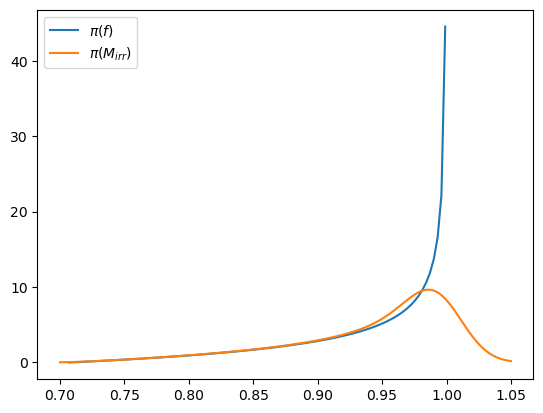

In [75]:
plt.plot(grid_f, pdf_f, label = r"$\pi(f)$")
plt.plot(grid_M, pdf_M, label = r"$\pi(M_{irr})$")
plt.legend()
plt.show()

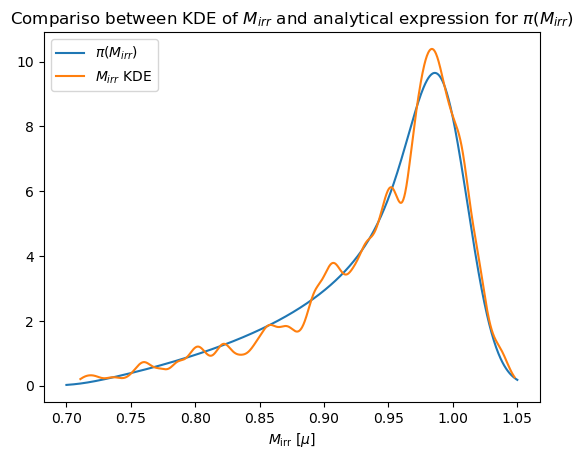

In [77]:
plt.plot(grid_M, pdf_M, label = r"$\pi(M_{irr})$")
plt.plot(xgrid,PDFtophat, label = r"$M_{irr}$ KDE")
plt.xlabel(r"$M_{\rm{irr}}$ $[\mu]$")
plt.title(r"Compariso between KDE of $M_{irr}$ and analytical expression for $\pi(M_{irr})$")
plt.legend()
plt.show()